In [1]:
import numpy as np
from simulate_bounds import MODE_DEGREE

from visualize_helpers import latexify, plot_fi_comparison

latexify()
FORMAT = "pdf"
continuous_cmaps = [
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "Blues",
    "viridis",
    "plasma",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "pink",
    "bone",
    "gray",
    "copper",
]

In [2]:
%matplotlib inline

In [3]:
selected_eps = [0.0, 0.04, 0.07, 0.1, 0.3]

# Mode leakage

In [4]:
# md = 4
# fig, _ = plot_mode_mixing_sweep(
#     measurement_basis(md),
#     selected_eps,
#     _mix_modes_via_unitary,
#     mode_degree=md,
#     mode_indices=[
#         i * md + j for (i, j) in [(0, 0), (0, 1), (0, 2), (0, 3), (2, 0), (2, 2)]
#     ],
# )

# Load data

In [5]:
coords = np.load("coordinates.npy")
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

baseline_ms = np.load("baseline_fi_ms.npy")
baseline_ms_inv = np.load("baseline_fi_ms_inv.npy")

fis = []
fis_inv = []
for mixing_eps in selected_eps:
    fis.append(np.load(f"fi_ms_eps_{mixing_eps:.2f}.npy"))
    fis_inv.append(np.load(f"fi_ms_inv_eps_{mixing_eps:.2f}.npy"))

# s param

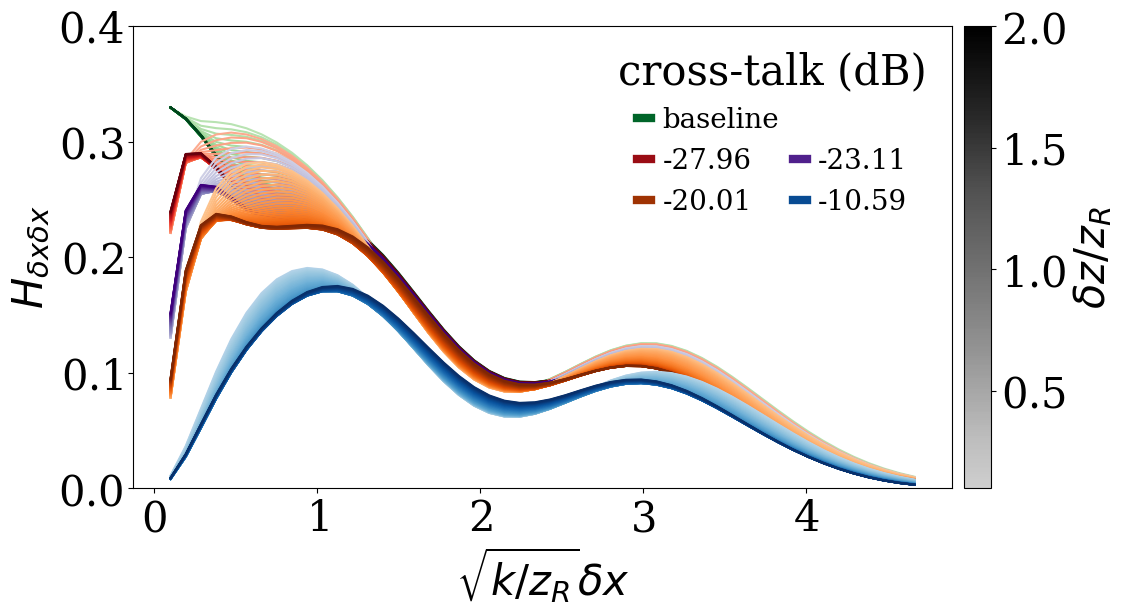

In [6]:
fig, axs = plot_fi_comparison(
    [np.sum(fi, axis=2)[:, :, 0, 0] for fi in fis],
    x_range,
    p_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    ylim=(0, 0.4),
    baseline_first=True,
)

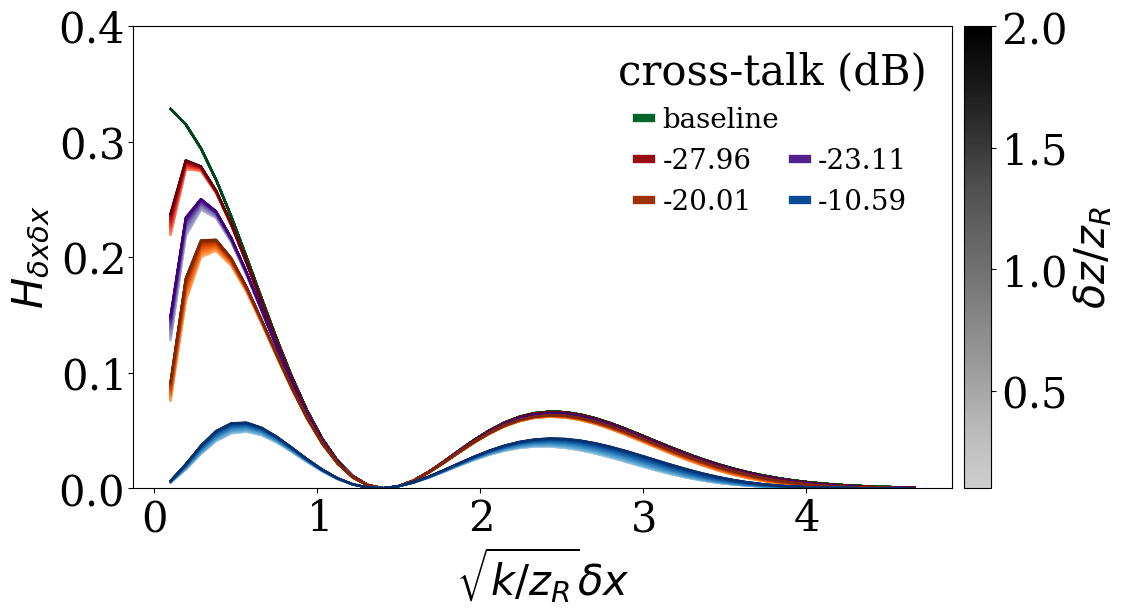

In [7]:
x_index = 1
y_index = 0
mode_index = x_index * MODE_DEGREE + y_index

fig, axs = plot_fi_comparison(
    [fi[:, :, mode_index, 0, 0] for fi in fis],
    x_range,
    p_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    ylim=(0, 0.4),
    baseline_first=True,
)

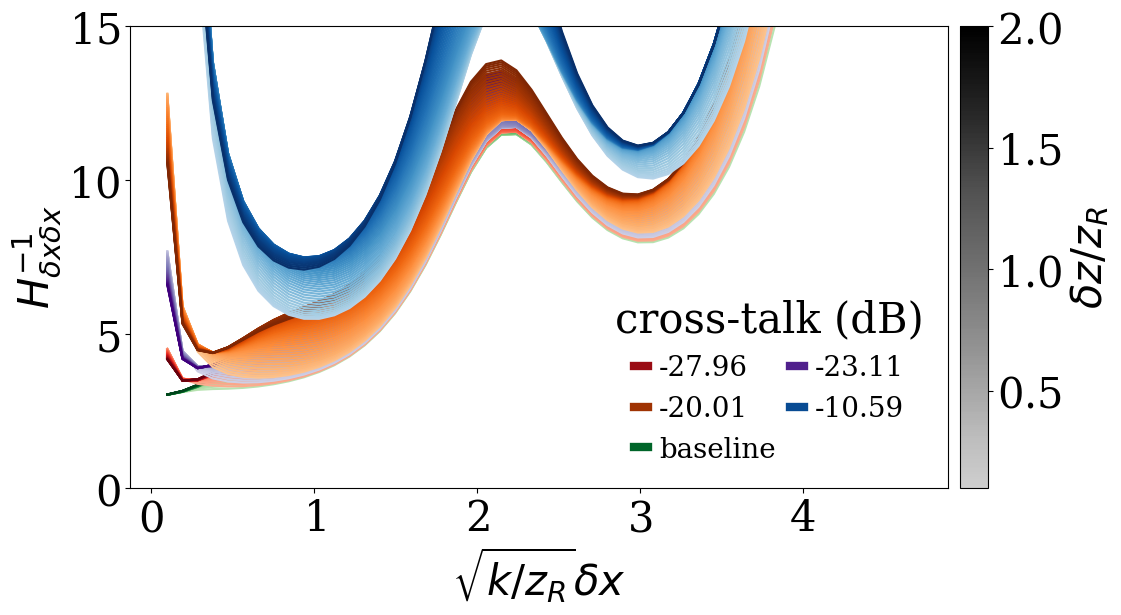

In [8]:
fig, axs = plot_fi_comparison(
    [fi_inv[:, :, 0, 0] for fi_inv in fis_inv],
    x_range,
    p_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H^{-1}_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    ylim=(0, 15),
)

# p param

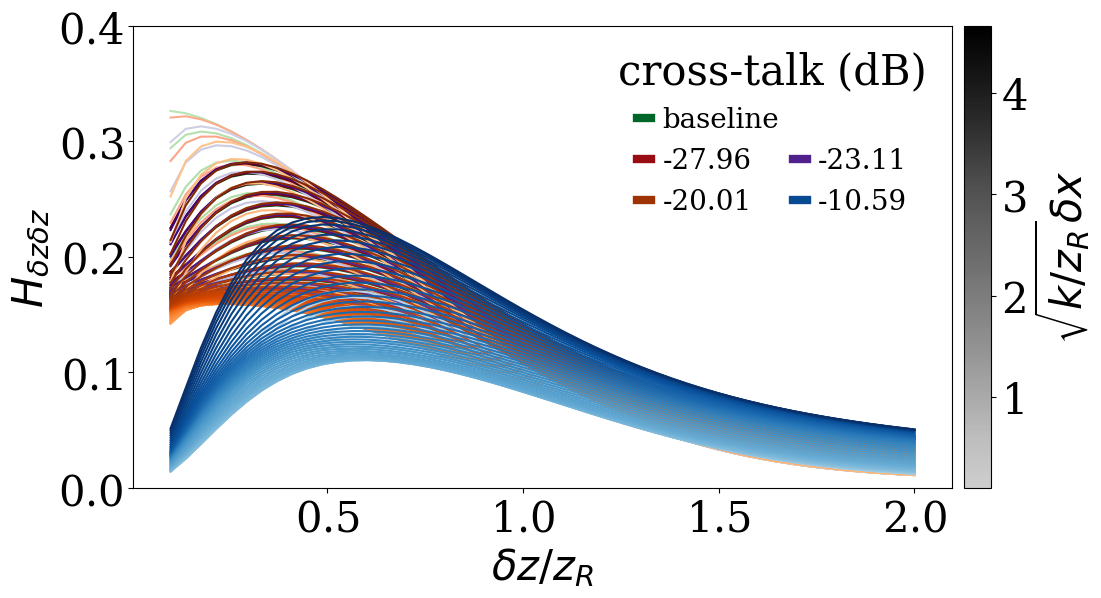

In [9]:
fig, axs = plot_fi_comparison(
    [np.transpose(np.sum(fi, axis=2)[:, :, 1, 1]) for fi in fis],
    p_range,
    x_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 0.4),
    baseline_first=True,
)

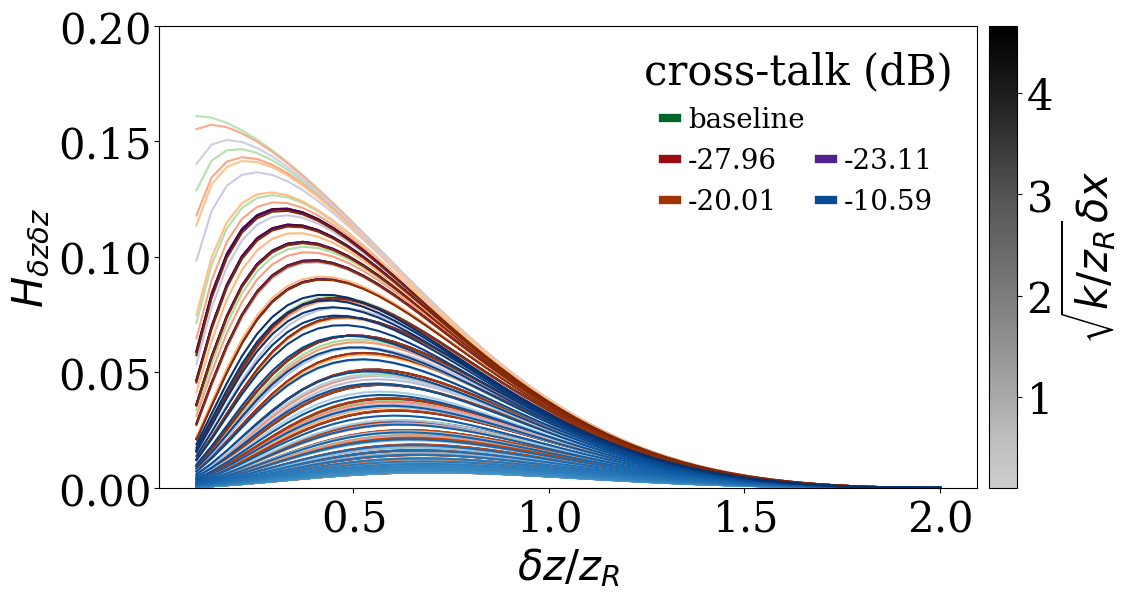

In [10]:
x_index = 2
y_index = 0
mode_index = x_index * MODE_DEGREE + y_index

fig, axs = plot_fi_comparison(
    [np.transpose(fi[:, :, mode_index, 1, 1]) for fi in fis],
    p_range,
    x_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 0.2),
    baseline_first=True,
)

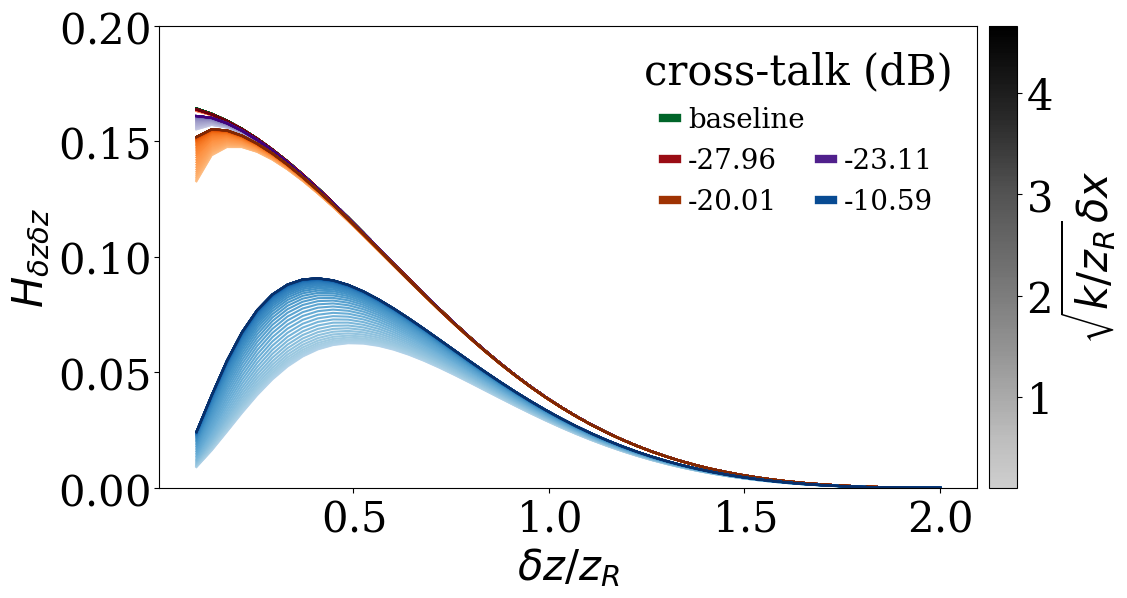

In [11]:
x_index = 0
y_index = 2
mode_index = x_index * MODE_DEGREE + y_index

fig, axs = plot_fi_comparison(
    [np.transpose(fi[:, :, mode_index, 1, 1]) for fi in fis],
    p_range,
    x_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 0.2),
    baseline_first=True,
)

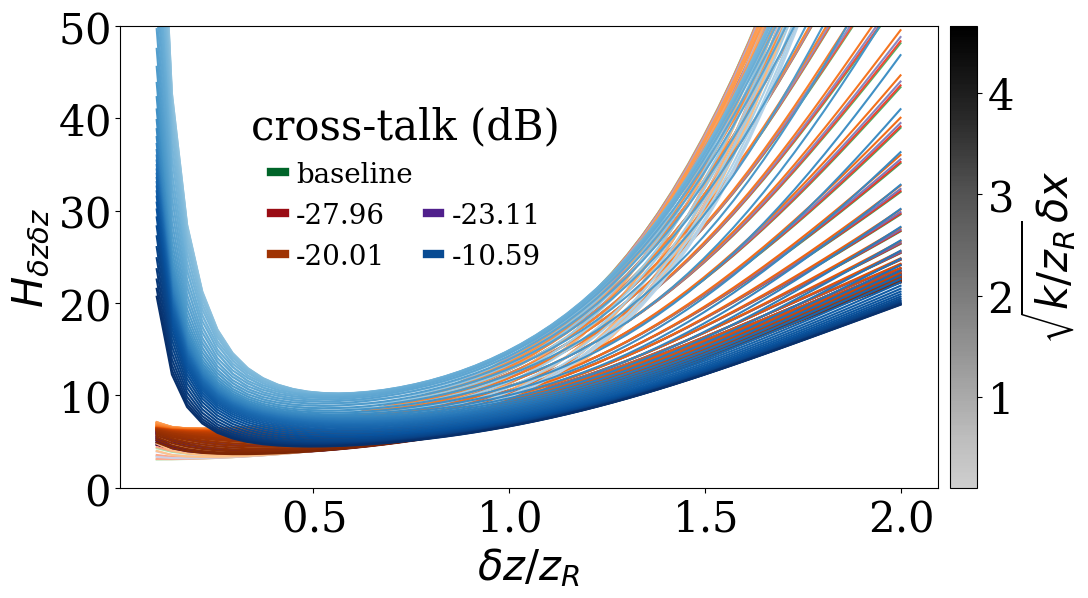

In [ ]:
fig, axs = plot_fi_comparison(
    [np.transpose(fi_inv[:, :, 1, 1]) for fi_inv in fis_inv],
    p_range,
    x_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 50),
    baseline_first=True,
)

leg = axs[0].get_legend()
handles = leg.legend_handles  # type: ignore
labels = [t.get_text() for t in leg.get_texts()]  # type: ignore
title = leg.get_title().get_text()  # type: ignore

axs[0].legend(
    handles=handles,
    labels=labels,
    title=title,
    frameon=False,
    ncol=2,
    handlelength=0.5,
    handletextpad=0.4,
    columnspacing=0.5,
    loc="center",
    bbox_to_anchor=(0.35, 0.65),
)